# Lab 01-05 · Integrals

Companion to chapter [01-05](../../chapters/01-05-integrals.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, shutil, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

## Part 1 — How fast do the rules converge?

Integrate $\int_0^1 e^x\,dx = e - 1$ with left, trapezoid, midpoint and Simpson rules for many $n$, and fit the slope of error against step size on log–log axes. (We avoid $\int_0^\pi\sin x\,dx$ here: its integrand is zero at both ends, which makes the left sum coincide with the trapezoid rule.)

**🔮 Predict** each rule's order (the slope).

left       fitted order (slope) = 0.99
trapezoid  fitted order (slope) = 2.00
midpoint   fitted order (slope) = 2.00
Simpson    fitted order (slope) = 4.00


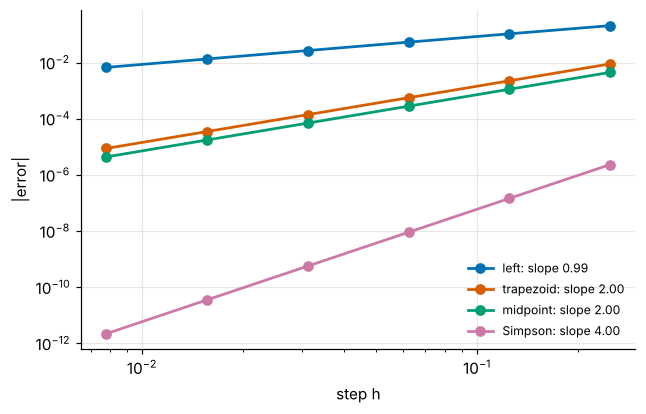

In [2]:
f, a, b, exact = np.exp, 0.0, 1.0, math.e - 1
def rules(n):
    x = np.linspace(a, b, n + 1); h = (b - a) / n
    left = h * f(x[:-1]).sum()
    trap = h * (f(x).sum() - 0.5 * (f(x[0]) + f(x[-1])))
    mid = h * f(x[:-1] + h / 2).sum()
    simp = (2 * mid + trap) / 3
    return left, trap, mid, simp
ns = np.array([4, 8, 16, 32, 64, 128])
errs = np.array([[abs(r - exact) for r in rules(n)] for n in ns])
hs = (b - a) / ns
plt.figure(figsize=(6.5, 4))
for k, name in enumerate(["left", "trapezoid", "midpoint", "Simpson"]):
    slope = np.polyfit(np.log(hs), np.log(errs[:, k]), 1)[0]
    plt.loglog(hs, errs[:, k], "o-", label=f"{name}: slope {slope:.2f}")
    print(f"{name:<10} fitted order (slope) = {slope:.2f}")
plt.xlabel("step h"); plt.ylabel("|error|"); plt.legend(fontsize=8); plt.show()

## Part 2 — A fuel gauge is an integral (with errors)

Simulate one week of the fitness band of Example 01-05.5 (5 mA for 2 min per hour, 0.5 mA otherwise) and a gauge whose current sensor has a 1% gain error and a 10 µA offset.

**🔮 Predict** the gauge's error in mAh after 7 days.

true charge used in 7 days: 109.2 mAh
gauge error after 7 days: 2.77 mAh (2.54 %)
  of which offset: 1.68 mAh, gain: 1.09 mAh


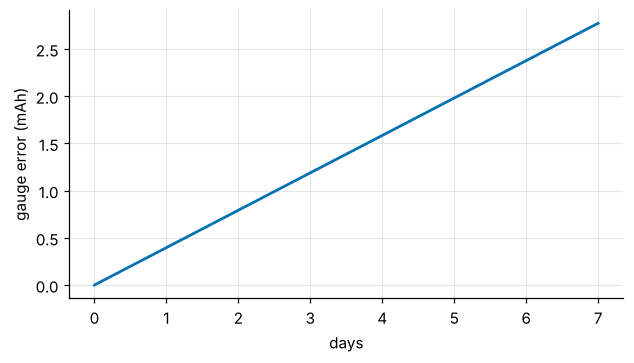

In [3]:
dt = 1.0                                   # s
t = np.arange(0, 7 * 24 * 3600, dt)
i_true = np.where((t % 3600) < 120, 5e-3, 0.5e-3)        # A
i_meas = 1.01 * i_true + 10e-6
q_true = np.cumsum(i_true) * dt / 3.6                  # mAh (A*s -> mAh: /3.6)
q_meas = np.cumsum(i_meas) * dt / 3.6
print(f"true charge used in 7 days: {q_true[-1]:.1f} mAh")
print(f"gauge error after 7 days: {q_meas[-1] - q_true[-1]:.2f} mAh "
      f"({100*(q_meas[-1]/q_true[-1]-1):.2f} %)")
print(f"  of which offset: {10e-6 * t[-1] / 3.6:.2f} mAh, gain: {0.01 * q_true[-1]:.2f} mAh")
plt.figure(figsize=(6.5, 3.4)); plt.plot(t / 86400, q_meas - q_true)
plt.xlabel("days"); plt.ylabel("gauge error (mAh)"); plt.show()

## Part 3 — Energy metering: how many samples per cycle?

**🔮 Predict** the smallest number of equally spaced samples per cycle that gives the exact average power of $v = 325\sin\omega t$, $i = 10\sin(\omega t - 30°)$, for an arbitrary starting phase.

In [4]:
P_exact = 0.5 * 325 * 10 * math.cos(math.pi / 6)
rng = np.random.default_rng(0)
for N in range(1, 7):
    worst = 0
    for _ in range(200):
        t0 = rng.uniform(0, 1 / 50)
        tk = t0 + np.arange(N) / (50 * N)
        p = (325 * np.sin(2 * math.pi * 50 * tk) * 10 * np.sin(2 * math.pi * 50 * tk - math.pi / 6)).mean()
        worst = max(worst, abs(p - P_exact))
    print(f"N = {N}: worst error over random start phases = {worst:9.3f} W")
print(f"exact average power = {P_exact:.1f} W")

N = 1: worst error over random start phases =  1624.995 W
N = 2: worst error over random start phases =  1624.992 W
N = 3: worst error over random start phases =     0.000 W
N = 4: worst error over random start phases =     0.000 W
N = 5: worst error over random start phases =     0.000 W
N = 6: worst error over random start phases =     0.000 W
exact average power = 1407.3 W


## Part 4 — ngspice: capacitors integrate, resistors take their half

`cap_charge.cir` and `integrator.cir` are checked by `python tools/run_spice.py 01-05` from the repository root. The cell below runs them directly if ngspice is installed.

In [5]:
if shutil.which("ngspice"):
    keys = ("v1_1m", "v1_3m", "e_r", "e_src", "e_c", "vo_2m", "pp2")
    for net in ["cap_charge.cir", "integrator.cir"]:
        out = subprocess.run(["ngspice", "-b", net], capture_output=True, text=True).stdout
        print(net)
        for l in out.splitlines():
            if "=" in l and l.split("=")[0].strip() in keys:
                print("   " + l.strip())
else:
    print("ngspice not found; see SETUP.md. Skipping.")

cap_charge.cir
   v1_1m               =  6.000000e+00
   v1_3m               =  1.000247e+00
   e_r                 =   1.24994e-03 from=  1.00000e-08 to=  2.00000e+00
   e_src               =   2.49998e-03 from=  1.00000e-08 to=  2.00000e+00
   e_c                 =  1.25000e-03


integrator.cir
   vo_2m               =  -9.999980e-01
   pp2                 =  5.000079e-01 from=  0.000000e+00 to=  5.000000e-03


## Your turn

1. In `cap_charge.cir`, change `R2` to 100 Ω and re-run. Predict the dissipated energy first.
2. In Part 2, remove the offset but keep the gain error. Which error source matters more for a week of standby?